# CatVTON - pipeline chấm điểm tự động

Chạy tuần tự từ trên xuống. Hai giai đoạn tách rời nhau:

- Giai đoạn 1 (cell #2b, #4): sinh ảnh trên cả 2 GPU (T4 x2),
  lưu ra đĩa, chạy tiếp được nếu bị ngắt.
- Giai đoạn 2 (cell #5-#8): đọc ảnh đã lưu và tính metric.

Chỉ cần sửa `PERSON_DIR` và `CLOTH_DIR` ở cell #3
(đường dẫn 2 folder ảnh), rồi Run All.
Không chạy cell API/ngrok trong notebook này (nó chặn kernel).

In [1]:
#1
import os, sys, glob, shutil, subprocess
os.chdir("/kaggle/working")

!pip install "huggingface_hub>=0.34.0,<2.0"
!pip install fvcore iopath yacs omegaconf cloudpickle
!pip install pycocotools av lpips torch-fidelity
!pip install ninja wheel matplotlib tabulate termcolor

# ===== detectron2 (DensePose trong CatVTON import trực tiếp) =====
D2_GIT = "git+https://github.com/facebookresearch/detectron2.git"
WHEEL_DIR = "/kaggle/working/wheels"
os.makedirs(WHEEL_DIR, exist_ok=True)

def sh(cmd, env=None):
    p = subprocess.run(cmd, env=env, capture_output=True, text=True)
    return p.returncode == 0, (p.stdout + p.stderr)[-2500:]

def d2_ok():
    """Chạy đúng 2 import mà CatVTON/DensePose cần."""
    return sh([
        sys.executable, "-c",
        "from detectron2.config import get_cfg; "
        "from detectron2.engine.defaults import DefaultPredictor",
    ])

def d2_install_wheel(path):
    ok, _ = sh([sys.executable, "-m", "pip", "install",
                "--no-deps", "--force-reinstall", path])
    return ok and d2_ok()[0]

def ensure_detectron2():
    if d2_ok()[0]:
        print("[detectron2] đã có sẵn")
        return

    # 1) wheel dựng sẵn (Kaggle dataset đã add, hoặc lần build trước)
    wheels = sorted(
        glob.glob("/kaggle/input/**/detectron2*.whl", recursive=True)
        + glob.glob(f"{WHEEL_DIR}/detectron2*.whl")
    )
    for w in wheels:
        if d2_install_wheel(w):
            print("[detectron2] cài từ wheel:", w)
            return

    # 2) build từ source: lần 1 tự động, lần 2 bản CPU-only
    #    (CPU-only vẫn đủ cho DensePose inference)
    env = {**os.environ, "MAX_JOBS": "4", "GIT_TERMINAL_PROMPT": "0"}
    env.pop("FORCE_CUDA", None)
    attempts = [
        ("auto", env),
        ("CPU-only", {**env, "CUDA_VISIBLE_DEVICES": ""}),
    ]
    for name, e in attempts:
        print(f"[detectron2] build từ source ({name}), ~5-10 phút ...")
        ok, log = sh([sys.executable, "-m", "pip", "wheel",
                      "--no-build-isolation", "--no-deps",
                      "-w", WHEEL_DIR, D2_GIT], e)
        if not ok:
            print(log)
            continue
        new = max(glob.glob(f"{WHEEL_DIR}/detectron2*.whl"),
                  key=os.path.getmtime)
        if d2_install_wheel(new):
            print("[detectron2] build + cài OK:", new)
            return
        print(d2_ok()[1])
    raise RuntimeError("Không cài được detectron2 - xem log phía trên")

ensure_detectron2()

# ===== tải code CatVTON =====
URL = "https://github.com/Zheng-Chong/CatVTON.git"
if not os.path.isdir("CatVTON"):
    try:
        subprocess.run(
            ["git", "clone", "--depth", "1", URL],
            env={**os.environ,
                 "GIT_TERMINAL_PROMPT": "0"},
            timeout=120, check=True,
        )
    except Exception as e:
        print("GitHub lỗi:", e)
        print("-> tải code từ HuggingFace Space")
        shutil.rmtree("CatVTON", ignore_errors=True)
        from huggingface_hub import snapshot_download
        snapshot_download(
            repo_type="space",
            repo_id="zhengchong/CatVTON",
            local_dir="/kaggle/working/CatVTON",
            ignore_patterns=["resource/*", "*.pyc"],
        )

%cd /kaggle/working/CatVTON
for f in ["utils.py", "model/pipeline.py",
          "model/cloth_masker.py"]:
    assert os.path.isfile(f), f"thiếu {f}"
print("Code CatVTON OK")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for fvcore: filename=fvcore-0.1.5.post20221221-py3-none-any.whl size=61447 sha256=f6690791655a2fb079084acfa65ac34d5515c95a9d6e9e6049159e06b6b5c254
  Stored in directory: /root/.cache/pip/wheels/6b/1b/9a/9f4843148961a522f56dbeaa5543071ac2389d9a079ec724ab
  Created wheel for iopath: filename=iopath-0.1.10-py3-none-any.whl size=31598 sha256=07b5985e6e599991eb3bb5003c5134e6ca66fa4c1e950e3aa5ffd0828f046cef
  Stored in directory: /root/.cache/pip/wheels/cd/c4/19/776124f304c8d9cb940cb164ec2ad635b42d9d1cf03217506d
Successfully built fvcore iopath
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [fvcore]2m3/4 [fvcore]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 130.6 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━

Cloning into 'CatVTON'...
fatal: could not read Username for 'https://github.com': terminal prompts disabled


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 131 files:   0%|          | 0/131 [00:00<?, ?it/s]

/kaggle/working/CatVTON
Code CatVTON OK


In [2]:
#2
import os, time, io, glob
import torch
from PIL import Image
from diffusers.image_processor import VaeImageProcessor
from huggingface_hub import snapshot_download
from model.cloth_masker import AutoMasker
from model.pipeline import CatVTONPipeline
from utils import init_weight_dtype, resize_and_crop, resize_and_padding

def find_local_dir(root, folder_name):
    """Tìm folder_name bên trong root, trả về path nếu tồn tại và có file."""
    if not os.path.isdir(root):
        return None
    for m in glob.glob(os.path.join(root, "**", folder_name), recursive=True):
        if os.path.isdir(m) and os.listdir(m):
            return m
    return None

DATASET_ROOT = "/kaggle/input/catvton-weights"
WORKING_ROOT = "/kaggle/working/catvton_weights"

catvton_local = find_local_dir(DATASET_ROOT, "CatVTON") or os.path.join(WORKING_ROOT, "CatVTON")
if os.path.isdir(catvton_local) and os.listdir(catvton_local):
    repo_path = catvton_local
    print(f"[cache] Dùng CatVTON weights có sẵn: {repo_path}")
else:
    print("[download] Chưa có cache, tải CatVTON từ HF Hub...")
    repo_path = snapshot_download(repo_id="zhengchong/CatVTON", local_dir=catvton_local)

sd_local = find_local_dir(DATASET_ROOT, "sd-inpainting") or os.path.join(WORKING_ROOT, "sd-inpainting")
if os.path.isdir(sd_local) and os.listdir(sd_local):
    base_ckpt_path = sd_local
    print(f"[cache] Dùng SD-inpainting weights có sẵn: {base_ckpt_path}")
else:
    print("[download] Chưa có cache, tải SD-inpainting từ HF Hub...")
    base_ckpt_path = snapshot_download(repo_id="booksforcharlie/stable-diffusion-inpainting", local_dir=sd_local)

pipeline = CatVTONPipeline(
    base_ckpt=base_ckpt_path,
    attn_ckpt=repo_path,
    attn_ckpt_version="mix",
    weight_dtype=init_weight_dtype("fp16"),
    use_tf32=True,
    device="cuda",
    skip_safety_check=True,
)
mask_processor = VaeImageProcessor(vae_scale_factor=8, do_normalize=False, do_binarize=True, do_convert_grayscale=True)
automasker = AutoMasker(densepose_ckpt=os.path.join(repo_path, "DensePose"), schp_ckpt=os.path.join(repo_path, "SCHP"), device="cuda")

# --- [OPT-1] Doi sang DPM++ 2M Karras scheduler ---
from diffusers import DPMSolverMultistepScheduler
pipeline.noise_scheduler = DPMSolverMultistepScheduler.from_config(
    pipeline.noise_scheduler.config,
    use_karras_sigmas=True,
    algorithm_type="dpmsolver++"
)
print("[OPT] Scheduler: DPM++ 2M Karras - OK")

# --- [OPT-2] Bat xFormers memory efficient attention ---
try:
    pipeline.unet.enable_xformers_memory_efficient_attention()
    print("[OPT] xFormers memory efficient attention - OK")
except Exception as e:
    print(f"[WARN] xFormers not available: {e}")

[download] Chưa có cache, tải CatVTON từ HF Hub...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

[download] Chưa có cache, tải SD-inpainting từ HF Hub...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

... (2 outputs left out)

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
An error occurred while trying to fetch /kaggle/working/catvton_weights/sd-inpainting: Error no file named diffusion_pytorch_model.safetensors found in directory /kaggle/working/catvton_weights/sd-inpainting.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


[OPT] Scheduler: DPM++ 2M Karras - OK
[WARN] xFormers not available: Refer to https://github.com/facebookresearch/xformers for more information on how to install xformers


In [3]:
#2b - bản CatVTON thứ hai trên GPU 1 (cần accelerator T4 x2)
HAVE_2GPU = torch.cuda.device_count() >= 2
print("Số GPU:", torch.cuda.device_count())

if HAVE_2GPU:
    pipeline_1 = CatVTONPipeline(
        base_ckpt=base_ckpt_path,
        attn_ckpt=repo_path,
        attn_ckpt_version="mix",
        weight_dtype=init_weight_dtype("fp16"),
        use_tf32=True,
        device="cuda:1",
        skip_safety_check=True,
    )
    automasker_1 = AutoMasker(
        densepose_ckpt=os.path.join(repo_path, "DensePose"),
        schp_ckpt=os.path.join(repo_path, "SCHP"),
        device="cuda:1",
    )
    pipeline_1.noise_scheduler = (
        DPMSolverMultistepScheduler.from_config(
            pipeline_1.noise_scheduler.config,
            use_karras_sigmas=True,
            algorithm_type="dpmsolver++",
        )
    )
else:
    print("[WARN] chỉ có 1 GPU -> chạy 1 worker")

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Số GPU: 2


An error occurred while trying to fetch /kaggle/working/catvton_weights/sd-inpainting: Error no file named diffusion_pytorch_model.safetensors found in directory /kaggle/working/catvton_weights/sd-inpainting.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


In [4]:
#3 - cấu hình chạy + đọc danh sách cặp (person, cloth)
import os, io, glob, json, time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm

# ===== CHỈ CẦN SỬA 2 DÒNG NÀY =====
# Đường dẫn 2 folder ảnh trong Kaggle (xem ở thanh Input
# bên phải, hoặc chạy: !ls /kaggle/input)
PERSON_DIR = "/kaggle/input/datasets/js042710/tuan6-vton-123/people"
CLOTH_DIR = "/kaggle/input/datasets/js042710/tuan6-vton-123/dress"
# ===================================

# --- tuỳ chọn (có thể giữ mặc định) ---
AUTO_CATEGORY = True    # tự nhận áo / quần-váy / đầm-bộ bằng CLIP
CATEGORY = "overall"    # chỉ dùng khi AUTO_CATEGORY = False
CATEGORY_OVERRIDE = {}  # sửa tay: {"quan_jean.jpg": "lower"}
N_SAMPLES = None          # None = chạy hết; 10 = chạy thử
RUN_NAME = "dpmpp_s20_g4.5"   # đổi tên khi thử cấu hình khác
SEED = 42
STEPS = 20
GUIDANCE = 4.5
BLUR = 9
W, H = 768, 1024

EVAL_ROOT = "/kaggle/working/eval"
RUN_DIR = f"{EVAL_ROOT}/{RUN_NAME}"
SUB = {
    k: f"{RUN_DIR}/{k}"
    for k in ["person", "cloth", "mask", "gen"]
}
for d in SUB.values():
    os.makedirs(d, exist_ok=True)

def stem(name):
    return os.path.splitext(name)[0]

def pair_id(person_name, cloth_name):
    return f"{stem(person_name)}__{stem(cloth_name)}"

IMG_EXT = (".jpg", ".jpeg", ".png", ".webp")

def list_imgs(d):
    return sorted(
        f for f in os.listdir(d)
        if f.lower().endswith(IMG_EXT)
    )

def build_pairs(person_dir, cloth_dir, seed=0):
    """Tự ghép cặp (người, áo) từ 2 folder.

    - >= 80% ảnh người có ảnh áo CÙNG TÊN FILE -> "paired"
      (coi như người đang mặc đúng chiếc áo đó).
    - Ngược lại -> "unpaired": mỗi người ghép ngẫu nhiên
      với 1 áo (seed cố định nên chạy lại ra y hệt).
    """
    persons = list_imgs(person_dir)
    cloths = list_imgs(cloth_dir)
    by_stem = {stem(c): c for c in cloths}
    same = [
        (p, by_stem[stem(p)])
        for p in persons if stem(p) in by_stem
    ]
    if len(same) >= 0.8 * len(persons):
        return same, "paired"
    rng = np.random.RandomState(seed)
    rows = [
        (p, cloths[rng.randint(len(cloths))])
        for p in persons
    ]
    return rows, "unpaired"

for d in (PERSON_DIR, CLOTH_DIR):
    if not os.path.isdir(d):
        print("Không thấy folder:", d)
        print("Trong /kaggle/input có:",
              os.listdir("/kaggle/input"))
        raise FileNotFoundError(d)

PAIRS, SETTING = build_pairs(PERSON_DIR, CLOTH_DIR)
if N_SAMPLES and N_SAMPLES < len(PAIRS):
    # seed cố định -> mọi run dùng cùng tập con
    rng = np.random.RandomState(0)
    idx = sorted(
        rng.choice(len(PAIRS), N_SAMPLES, replace=False))
    PAIRS = [PAIRS[i] for i in idx]
print(f"{len(PAIRS)} cặp | setting={SETTING} | run={RUN_NAME}")
if SETTING == "unpaired":
    print("Không có ảnh gốc làm chuẩn -> bỏ qua SSIM/LPIPS thường")

# --- nhận loại đồ cho TỪNG ảnh áo: upper | lower | overall ---
# upper = áo | lower = quần/váy | overall = đầm/bộ/cả bộ đồ
def pad_square(img, fill=255):
    s = max(img.size)
    canvas = Image.new("RGB", (s, s), (fill,) * 3)
    canvas.paste(
        img,
        ((s - img.width) // 2, (s - img.height) // 2),
    )
    return canvas

CAT_PROMPTS = {
    "upper": "a photo of a top, shirt, blouse, "
             "jacket or sweater",
    "lower": "a photo of pants, trousers, jeans, "
             "shorts or a skirt",
    "overall": "a photo of a dress, a jumpsuit "
               "or a full outfit",
}

def detect_categories(cloth_names):
    """Zero-shot CLIP (chạy CPU). Trả về {tên: (loại, độ tin cậy)}."""
    from transformers import CLIPModel, CLIPProcessor
    mid = "openai/clip-vit-base-patch32"
    model = CLIPModel.from_pretrained(mid).eval()
    proc = CLIPProcessor.from_pretrained(mid)
    keys = list(CAT_PROMPTS)
    texts = list(CAT_PROMPTS.values())
    res = {}
    for n in cloth_names:
        img = Image.open(f"{CLOTH_DIR}/{n}").convert("RGB")
        x = proc(
            text=texts, images=pad_square(img),
            return_tensors="pt", padding=True,
        )
        with torch.no_grad():
            p = model(**x).logits_per_image.softmax(-1)[0]
        res[n] = (keys[int(p.argmax())], float(p.max()))
    return res

cloth_names = sorted({c for _, c in PAIRS})
if AUTO_CATEGORY:
    det = detect_categories(cloth_names)
else:
    det = {n: (CATEGORY, 1.0) for n in cloth_names}
CAT_OF = {n: det[n][0] for n in cloth_names}
CAT_OF.update(CATEGORY_OVERRIDE)
CAT_OF_ID = {pair_id(p, c): CAT_OF[c] for p, c in PAIRS}
with open(f"{RUN_DIR}/categories.json", "w") as f:
    json.dump(CAT_OF, f, ensure_ascii=False, indent=1)

print("Số ảnh áo theo loại:",
      {k: list(CAT_OF[n] for n in cloth_names).count(k)
       for k in CAT_PROMPTS})
if len(cloth_names) <= 60:
    for n in cloth_names:
        cat, conf = det[n]
        note = ""
        if n in CATEGORY_OVERRIDE:
            note = " (sửa tay)"
        elif AUTO_CATEGORY and conf < 0.6:
            note = "  <- nên kiểm tra"
        print(f"{n[:28]:28s} {CAT_OF[n]:8s} {conf:.2f}{note}")

100 cặp | setting=unpaired | run=dpmpp_s20_g4.5
Không có ảnh gốc làm chuẩn -> bỏ qua SSIM/LPIPS thường


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (4 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Số ảnh áo theo loại: {'upper': 58, 'lower': 0, 'overall': 5}


In [5]:
#4 - Giai đoạn 1: sinh ảnh (chạy tiếp được nếu bị ngắt)
CONFIG = dict(
    run=RUN_NAME,
    setting=SETTING,
    category="auto" if AUTO_CATEGORY else CATEGORY,
    steps=STEPS,
    guidance=GUIDANCE,
    blur=BLUR,
    seed=SEED,
    scheduler=type(pipeline.noise_scheduler).__name__,
    n_pairs=len(PAIRS),
)
with open(f"{RUN_DIR}/config.json", "w") as f:
    json.dump(CONFIG, f, indent=1)

from concurrent.futures import ThreadPoolExecutor

# mỗi worker = (pipeline, automasker, chỉ số GPU)
# pipeline/automasker: cell #2 | pipeline_1/automasker_1: cell #2b
WORKERS = [(pipeline, automasker, 0)]
if HAVE_2GPU:
    WORKERS.append((pipeline_1, automasker_1, 1))
print(f"{len(WORKERS)} worker")

def generate_one(pn, cn, pipe, masker, gpu):
    pid = pair_id(pn, cn)
    gen_path = f"{SUB['gen']}/{pid}.png"
    if os.path.exists(gen_path):
        return 0
    with torch.cuda.device(gpu):
        person = Image.open(
            f"{PERSON_DIR}/{pn}").convert("RGB")
        cloth = Image.open(
            f"{CLOTH_DIR}/{cn}").convert("RGB")
        person = resize_and_crop(person, (W, H))
        cloth = resize_and_padding(cloth, (W, H))
        mask = masker(person, CAT_OF[cn])["mask"]
        mask_blur = mask_processor.blur(
            mask, blur_factor=BLUR)
        g = torch.Generator(
            device=f"cuda:{gpu}").manual_seed(SEED)
        out = pipe(
            image=person,
            condition_image=cloth,
            mask=mask_blur,
            num_inference_steps=STEPS,
            guidance_scale=GUIDANCE,
            generator=g,
        )[0]
    if out.size != (W, H):
        out = out.resize((W, H), Image.LANCZOS)
    # lưu mask THÔ (chưa blur); gen lưu cuối cùng để làm dấu "xong"
    person.save(f"{SUB['person']}/{pid}.png")
    cloth.save(f"{SUB['cloth']}/{pid}.png")
    mask.convert("L").save(f"{SUB['mask']}/{pid}.png")
    out.save(gen_path)
    return 1

def run_shard(w):
    pipe, masker, gpu = WORKERS[w]
    shard = PAIRS[w::len(WORKERS)]
    n_new = 0
    for pn, cn in tqdm(shard, desc=f"gpu{gpu}",
                       position=w):
        try:
            n_new += generate_one(
                pn, cn, pipe, masker, gpu)
        except Exception as e:
            print(f"[GPU{gpu}] SKIP {pn} / {cn}: {e}")
    return n_new

t0 = time.time()
with ThreadPoolExecutor(len(WORKERS)) as ex:
    n_new = sum(ex.map(run_shard, range(len(WORKERS))))
print(f"Xong: {n_new} ảnh mới trong {time.time() - t0:.0f}s")

2 worker


gpu0:   0%|          | 0/50 [00:00<?, ?it/s]

gpu1:   0%|          | 0/50 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W1114 05:56:13.255000 50 torch/fx/_symbolic_trace.py:53] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.
W1114 05:56:13.256000 50 torch/fx/_symbolic_trace.py:53] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


  0%|          | 0/20 [00:00<?, ?it/s]


  0%|          | 0/20 [00:00<?, ?it/s]

  5%|▌         | 1/20 [00:01<00

Xong: 100 ảnh mới trong 2570s


In [6]:
#5 - Giai đoạn 2: nạp mô hình dùng để đo
import lpips
from skimage.metrics import structural_similarity
from transformers import (
    AutoModel, AutoImageProcessor,
    CLIPModel, CLIPImageProcessor,
)

# Tuỳ chọn: nhả VRAM của CatVTON trước khi nạp mô hình đo
# del pipeline, automasker, pipeline_1, automasker_1
# torch.cuda.empty_cache()

dev = "cuda" if torch.cuda.is_available() else "cpu"

LPIPS_NET = "alex"
LPIPS_MARGIN = 16   # px bỏ thêm quanh mask khi tính LPIPS ngoài mask

lp_full = lpips.LPIPS(net=LPIPS_NET).to(dev).eval()
lp_map = lpips.LPIPS(net=LPIPS_NET, spatial=True).to(dev).eval()

CLIP_ID = "openai/clip-vit-large-patch14"
DINO_ID = "facebook/dino-vits16"
clip_model = CLIPModel.from_pretrained(CLIP_ID).to(dev).eval()
clip_proc = CLIPImageProcessor.from_pretrained(CLIP_ID)
dino_model = AutoModel.from_pretrained(DINO_ID).to(dev).eval()
dino_proc = AutoImageProcessor.from_pretrained(DINO_ID)

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 233MB/s] 


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [on]
Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth


config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

... (6 outputs left out)

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: facebook/dino-vits16
Key                 | Status  | 
--------------------+---------+-
pooler.dense.bias   | MISSING | 
pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


preprocessor_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

In [7]:
#6 - các hàm metric
def to_tensor(img):
    """PIL RGB -> tensor (1,3,H,W) trong [-1, 1]."""
    x = torch.from_numpy(np.array(img)).float()
    x = x.permute(2, 0, 1)[None] / 127.5 - 1.0
    return x.to(dev)

def dilate(mask_bool, k):
    """Nở mask k pixel. mask_bool: numpy (H,W) bool."""
    m = torch.from_numpy(mask_bool).float()[None, None].to(dev)
    if k > 0:
        m = F.max_pool2d(m, 2 * k + 1, stride=1, padding=k)
    return m[0, 0] > 0.5

@torch.no_grad()
def lpips_full(a, b):
    return lp_full(to_tensor(a), to_tensor(b)).item()

@torch.no_grad()
def lpips_outside(a, b, mask_bool, k=LPIPS_MARGIN):
    """LPIPS chỉ lấy trung bình ở vùng NGOÀI mask (đã nở k px)."""
    d = lp_map(to_tensor(a), to_tensor(b))[0, 0]   # (H, W)
    keep = ~dilate(mask_bool, k)
    if keep.sum() == 0:
        return float("nan")
    return d[keep].mean().item()

def ssim_score(a, b):
    return structural_similarity(
        np.asarray(a), np.asarray(b),
        channel_axis=2, data_range=255,
    )

def to_square(img, fill=255):
    """Đệm trắng thành hình vuông để CLIP/DINO không bị cắt giữa."""
    s = max(img.size)
    canvas = Image.new("RGB", (s, s), (fill,) * 3)
    canvas.paste(
        img,
        ((s - img.width) // 2, (s - img.height) // 2),
    )
    return canvas

def crop_box(mask_bool, pad=8):
    """Hộp bao quanh mask, trả về None nếu mask rỗng."""
    ys, xs = np.where(mask_bool)
    if len(ys) == 0:
        return None
    h, w = mask_bool.shape
    return (
        int(max(xs.min() - pad, 0)),
        int(max(ys.min() - pad, 0)),
        int(min(xs.max() + pad + 1, w)),
        int(min(ys.max() + pad + 1, h)),
    )

@torch.no_grad()
def embed_clip(imgs):
    imgs = [to_square(i) for i in imgs]
    px = clip_proc(images=imgs, return_tensors="pt")
    pv = px["pixel_values"].to(dev)
    v = clip_model.vision_model(pixel_values=pv).pooler_output
    f = clip_model.visual_projection(v)
    return F.normalize(f.float(), dim=-1)

@torch.no_grad()
def embed_dino(imgs):
    imgs = [to_square(i) for i in imgs]
    px = dino_proc(images=imgs, return_tensors="pt")
    out = dino_model(pixel_values=px["pixel_values"].to(dev))
    f = out.last_hidden_state[:, 0]
    return F.normalize(f.float(), dim=-1)

def cos(e, i, j):
    return (e[i] * e[j]).sum().item()

In [8]:
#7 - chấm điểm từng ảnh -> scores_per_image.csv
def load_rgb(kind, pid):
    return Image.open(f"{SUB[kind]}/{pid}.png").convert("RGB")

def score_one(pid):
    gen = load_rgb("gen", pid)
    person = load_rgb("person", pid)
    cloth = load_rgb("cloth", pid)
    m = np.asarray(Image.open(f"{SUB['mask']}/{pid}.png")) > 127
    row = {"id": pid, "category": CAT_OF_ID[pid]}

    # ngoài mask: gen phải giống ảnh người đầu vào (cả paired lẫn unpaired)
    row["lpips_out"] = lpips_outside(gen, person, m)

    # cần ảnh gốc làm ground truth -> chỉ paired
    if SETTING == "paired":
        row["ssim"] = ssim_score(gen, person)
        row["lpips"] = lpips_full(gen, person)

    # CLIP/DINO trên vùng áo: [0]=gen, [1]=ảnh áo, [2]=người gốc
    box = crop_box(m)
    g = gen.crop(box) if box else gen
    p = person.crop(box) if box else person
    imgs = [g, cloth, p]
    ec, ed = embed_clip(imgs), embed_dino(imgs)
    row["clip_cloth"] = cos(ec, 0, 1)
    row["dino_cloth"] = cos(ed, 0, 1)
    if SETTING == "paired":
        row["clip_gt"] = cos(ec, 0, 2)
        row["dino_gt"] = cos(ed, 0, 2)
    return row

ids = [pair_id(p, c) for p, c in PAIRS]
ids = [i for i in ids if os.path.exists(f"{SUB['gen']}/{i}.png")]
print(f"Chấm {len(ids)}/{len(PAIRS)} ảnh")

df = pd.DataFrame([score_one(i) for i in tqdm(ids)])
df.to_csv(f"{RUN_DIR}/scores_per_image.csv", index=False)
num = df.drop(columns="id")
print(num.groupby("category").mean().round(4).T)
print(num["category"].value_counts().to_dict())
num.mean(numeric_only=True).round(4)

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.7MB            

Chấm 100/100 ảnh


model.safetensors: downloading bytes:           |  0.00B            

  0%|          | 0/100 [00:00<?, ?it/s]

category    overall   upper
lpips_out    0.0436  0.0335
clip_cloth   0.7803  0.7551
dino_cloth   0.4462  0.4970
{'upper': 92, 'overall': 8}


lpips_out     0.0343
clip_cloth    0.7571
dino_cloth    0.4929
dtype: float64

In [9]:
#8 - FID/KID trên cả thư mục + tổng hợp -> scores_summary.json
import torch_fidelity

n_gen = len(os.listdir(SUB["gen"]))
if n_gen != len(df):
    print(f"[WARN] thư mục gen có {n_gen} ảnh nhưng chấm {len(df)}")

fk = torch_fidelity.calculate_metrics(
    input1=SUB["gen"],       # ảnh sinh ra
    input2=SUB["person"],    # ảnh thật (người, đã resize như pipeline)
    cuda=torch.cuda.is_available(),
    fid=True,
    kid=True,
    kid_subset_size=min(1000, n_gen),
    batch_size=32,
    verbose=False,
)

with open(f"{RUN_DIR}/config.json") as f:
    cfg = json.load(f)

summary = {
    "run": RUN_NAME,
    "n": len(df),
    **df.drop(columns="id").mean(numeric_only=True).to_dict(),
    "n_by_category": df["category"].value_counts().to_dict(),
    "fid": fk["frechet_inception_distance"],
    "kid_mean": fk["kernel_inception_distance_mean"],
    "kid_std": fk["kernel_inception_distance_std"],
    "config": cfg,
}
with open(f"{RUN_DIR}/scores_summary.json", "w") as f:
    json.dump(summary, f, indent=1)
pd.Series({k: v for k, v in summary.items() if k != "config"})

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth


run                           dpmpp_s20_g4.5
n                                        100
lpips_out                           0.034278
clip_cloth                          0.757123
dino_cloth                           0.49292
n_by_category    {'upper': 92, 'overall': 8}
fid                               111.177524
kid_mean                            0.055299
kid_std                                  0.0
dtype: object

In [10]:
#9 - so sánh nhiều run (ablation)
def compare_runs(root=EVAL_ROOT):
    rows = []
    for p in sorted(glob.glob(f"{root}/*/scores_summary.json")):
        with open(p) as f:
            s = json.load(f)
        cfg = s.pop("config", {})
        rows.append({
            **s,
            **{f"cfg_{k}": v for k, v in cfg.items()
               if k not in ("run", "n_pairs")},
        })
    return pd.DataFrame(rows).set_index("run").round(4)

compare_runs()

,n,lpips_out,clip_cloth,dino_cloth,n_by_category,fid,kid_mean,kid_std,cfg_setting,cfg_category,cfg_steps,cfg_guidance,cfg_blur,cfg_seed,cfg_scheduler
run,,,,,,,,,,,,,,,
dpmpp_s20_g4.5,100,0.0343,0.7571,0.4929,"{'upper': 92, 'overall': 8}",111.1775,0.0553,0.0,unpaired,auto,20,4.5,9,42,DPMSolverMultistepScheduler


In [11]:
import matplotlib.pyplot as plt
show = ids[:4]
fig, ax = plt.subplots(len(show), 3, figsize=(9, 4 * len(show)), squeeze=False)
for r, pid in enumerate(show):
    for c, k in enumerate(["person", "cloth", "gen"]):
        ax[r, c].imshow(load_rgb(k, pid))
        ax[r, c].axis("off")
        if r == 0:
            ax[r, c].set_title(k)
plt.tight_layout()
plt.show()

Nhóm,Metric,Đo cái gì,Hướng,Mean,Std,Median,Min,Max,Đạt (%),Tham chiếu,Kết luận
A. Giữ nguyên vùng ngoài áo,LPIPS ngoài mask,"Ảnh sinh khác ảnh người gốc bao nhiêu ở nền, mặt, tay",↓ thấp tốt,0.0343,0.0165,0.0323,0.0146,0.1684,99%,"<0.05 tốt, <0.1 chấp nhận",TỐT
B. Áo có được chuyển sang không,CLIP - ảnh sinh vs áo,Vùng áo trên ảnh sinh giống áo cần thử,↑ cao tốt,0.7571,0.0610,0.7592,0.6005,0.8744,–,,–
B. Áo có được chuyển sang không,CLIP - ảnh gốc vs áo,Baseline: người chưa thử đồ giống áo bao nhiêu,(mốc so),0.6772,0.0590,0.6764,0.3960,0.7929,–,,–
B. Áo có được chuyển sang không,CLIP - mức tăng,Ảnh sinh trừ baseline; dương = áo đã được chuyển,↑ dương tốt,0.0799,0.0689,0.0705,-0.0597,0.2756,88%,>0 ở ≥80% ảnh,TỐT
B. Áo có được chuyển sang không,DINO - ảnh sinh vs áo,Vùng áo trên ảnh sinh giống áo cần thử,↑ cao tốt,0.4929,0.1260,0.5006,0.2046,0.8443,–,,–
B. Áo có được chuyển sang không,DINO - ảnh gốc vs áo,Baseline: người chưa thử đồ giống áo bao nhiêu,(mốc so),0.3533,0.0949,0.3482,0.1541,0.6259,–,,–
B. Áo có được chuyển sang không,DINO - mức tăng,Ảnh sinh trừ baseline; dương = áo đã được chuyển,↑ dương tốt,0.1396,0.1345,0.1285,-0.1445,0.4243,84%,>0 ở ≥80% ảnh,TỐT
D. Chất lượng cả bộ ảnh,FID,Phân phối ảnh sinh so với ảnh người thật,↓ thấp tốt,111.18,–,–,–,–,–,cần ≥500 ảnh,KHÔNG ĐÁNG TIN (n=100 < 500)
D. Chất lượng cả bộ ảnh,KID,Phân phối ảnh sinh so với ảnh người thật,↓ thấp tốt,0.0553,0.0000,–,–,–,–,cần ≥500 ảnh,KHÔNG ĐÁNG TIN (n=100 < 500)


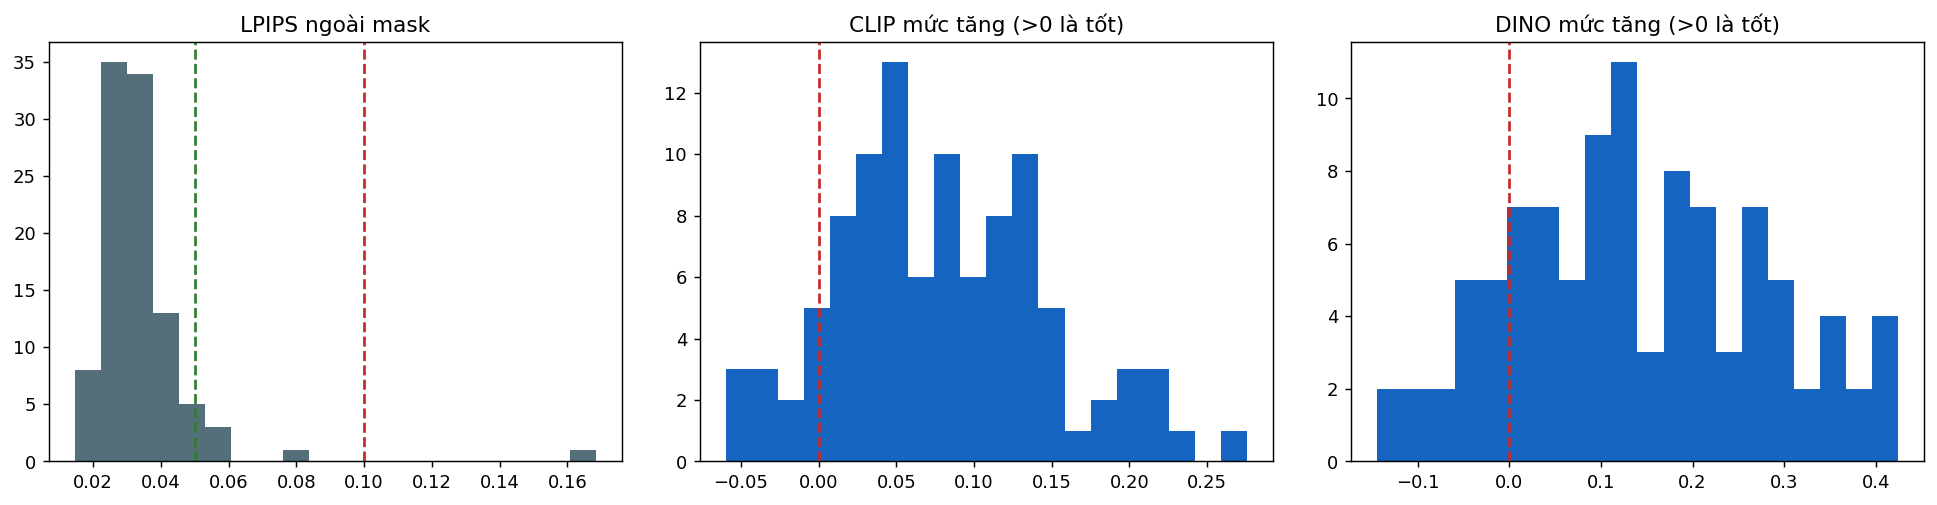

id,category,lpips_out,clip_cloth,clip_base,clip_gain,dino_cloth,dino_base,dino_gain
000456_0__c74,upper,0.0242,0.6648,0.7245,-0.0597,0.5142,0.2394,0.2748
000097_0__c70,upper,0.0339,0.7150,0.7645,-0.0495,0.3687,0.3437,0.0250
000118_0__c88,upper,0.0372,0.6005,0.6450,-0.0446,0.2046,0.3111,-0.1065
000303_0__c64,upper,0.0385,0.6634,0.7040,-0.0406,0.4026,0.3682,0.0344
000750_0__c99,upper,0.0263,0.7369,0.7765,-0.0396,0.3880,0.3600,0.0280
000696_0__c20,upper,0.0391,0.7659,0.7929,-0.0270,0.5020,0.4390,0.0629
000968_0__c48,upper,0.0355,0.7729,0.7859,-0.0129,0.3253,0.3385,-0.0132
000907_0__c99,upper,0.0289,0.7060,0.7175,-0.0115,0.3785,0.3321,0.0463
000466_0__c23,upper,0.0196,0.7131,0.7223,-0.0093,0.4786,0.3450,0.1336
000339_0__c49,upper,0.0276,0.7524,0.7567,-0.0043,0.4802,0.3624,0.1178


,n,lpips_out,clip_cloth,clip_gain,dino_cloth,dino_gain
category,,,,,,
overall,8,0.0436,0.7803,0.0975,0.4462,0.0821
upper,92,0.0335,0.7551,0.0784,0.4970,0.1446


Đã lưu: /kaggle/working/eval/dpmpp_s20_g4.5/report.html | /kaggle/working/eval/dpmpp_s20_g4.5/summary_table.csv | /kaggle/working/eval/dpmpp_s20_g4.5/report_chart.png


In [12]:
#11 - BÁO CÁO METRICS: bảng tổng hợp + biểu đồ + nhận định
# Dán vào CUỐI notebook, chạy sau cell #8. Không sinh lại ảnh.
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Image as IPyImage

# ----- ngưỡng nhận định (quy tắc kinh nghiệm của mình, chỉnh thoải mái) -----
T_LPIPS_GOOD, T_LPIPS_OK = 0.05, 0.10   # LPIPS ngoài mask
T_PASS_GOOD, T_PASS_OK = 0.80, 0.50     # tỉ lệ ảnh đạt
N_FID_MIN = 500                         # dưới mức này FID/KID không đáng tin
N_PER_IMAGE_PLOT = 40                   # nhiều hơn -> vẽ histogram thay vì từng ảnh

# ----- 1) baseline: ảnh người GỐC (chưa thử đồ) so với ảnh áo -----
def base_scores(pid):
    person, cloth = load_rgb("person", pid), load_rgb("cloth", pid)
    m = np.asarray(Image.open(f"{SUB['mask']}/{pid}.png")) > 127
    box = crop_box(m)
    p = person.crop(box) if box else person
    ec, ed = embed_clip([p, cloth]), embed_dino([p, cloth])
    return cos(ec, 0, 1), cos(ed, 0, 1)

d = df.copy()
b = [base_scores(i) for i in d["id"]]
d["clip_base"] = [x[0] for x in b]
d["dino_base"] = [x[1] for x in b]
d["clip_gain"] = d["clip_cloth"] - d["clip_base"]
d["dino_gain"] = d["dino_cloth"] - d["dino_base"]
n = len(d)
cfg = globals().get("CONFIG", {})

# ----- 2) dựng bảng tổng hợp -----
def fmt(x, k=4):
    return "–" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{x:.{k}f}"

def level(p):
    return "TỐT" if p >= T_PASS_GOOD else ("CHẤP NHẬN" if p >= T_PASS_OK else "CHƯA ỔN")

rows = []
def add_series(group, name, what, better, s, ref="", pass_frac=None, status="–"):
    s = s.dropna()
    rows.append({
        "Nhóm": group, "Metric": name, "Đo cái gì": what, "Hướng": better,
        "Mean": fmt(s.mean()), "Std": fmt(s.std(ddof=0)),
        "Median": fmt(s.median()), "Min": fmt(s.min()), "Max": fmt(s.max()),
        "Đạt (%)": "–" if pass_frac is None else f"{100 * pass_frac:.0f}%",
        "Tham chiếu": ref, "Kết luận": status,
    })

GA = "A. Giữ nguyên vùng ngoài áo"
GB = "B. Áo có được chuyển sang không"
GC = "D. Chất lượng cả bộ ảnh"
GD = "C. So với ảnh gốc (paired)"

lp_mean = d["lpips_out"].mean()
lp_status = ("TỐT" if lp_mean < T_LPIPS_GOOD
             else "CHẤP NHẬN" if lp_mean < T_LPIPS_OK else "CHƯA ỔN")
add_series(GA, "LPIPS ngoài mask", "Ảnh sinh khác ảnh người gốc bao nhiêu ở nền, mặt, tay",
           "↓ thấp tốt", d["lpips_out"],
           ref=f"<{T_LPIPS_GOOD} tốt, <{T_LPIPS_OK} chấp nhận",
           pass_frac=(d["lpips_out"] < T_LPIPS_OK).mean(), status=lp_status)

gain_status = {}
for nm, gen, base, gain in [("CLIP", "clip_cloth", "clip_base", "clip_gain"),
                            ("DINO", "dino_cloth", "dino_base", "dino_gain")]:
    add_series(GB, f"{nm} - ảnh sinh vs áo", "Vùng áo trên ảnh sinh giống áo cần thử",
               "↑ cao tốt", d[gen])
    add_series(GB, f"{nm} - ảnh gốc vs áo", "Baseline: người chưa thử đồ giống áo bao nhiêu",
               "(mốc so)", d[base])
    pf = (d[gain] > 0).mean()
    gain_status[nm] = level(pf)
    add_series(GB, f"{nm} - mức tăng", "Ảnh sinh trừ baseline; dương = áo đã được chuyển",
               "↑ dương tốt", d[gain],
               ref=f">0 ở ≥{int(T_PASS_GOOD * 100)}% ảnh", pass_frac=pf,
               status=gain_status[nm])

if SETTING == "paired":
    for lab, col, hint, better in [
        ("SSIM", "ssim", "Giống ảnh gốc về cấu trúc", "↑"),
        ("LPIPS toàn ảnh", "lpips", "Khác ảnh gốc về cảm nhận", "↓"),
        ("CLIP vs ảnh gốc", "clip_gt", "Vùng áo giống ảnh thật", "↑"),
        ("DINO vs ảnh gốc", "dino_gt", "Vùng áo giống ảnh thật", "↑")]:
        if col in d:
            add_series(GD, lab, hint, better, d[col], ref="so giữa các run")

if "summary" in globals():
    unreliable = n < N_FID_MIN
    st = f"KHÔNG ĐÁNG TIN (n={n} < {N_FID_MIN})" if unreliable else "so giữa các run"
    for lab, key, k in [("FID", "fid", 2), ("KID", "kid_mean", 4)]:
        rows.append({
            "Nhóm": GC, "Metric": lab,
            "Đo cái gì": "Phân phối ảnh sinh so với ảnh người thật",
            "Hướng": "↓ thấp tốt", "Mean": fmt(float(summary[key]), k),
            "Std": fmt(float(summary["kid_std"]), 4) if key == "kid_mean" else "–",
            "Median": "–", "Min": "–", "Max": "–", "Đạt (%)": "–",
            "Tham chiếu": f"cần ≥{N_FID_MIN} ảnh", "Kết luận": st})

table = pd.DataFrame(rows)

# ----- 3) nhận định tổng -----
core = [lp_status, gain_status["CLIP"], gain_status["DINO"]]
if all(c == "TỐT" for c in core):
    overall, ocol = "ỔN", "#2e7d32"
elif any(c == "CHƯA ỔN" for c in core):
    overall, ocol = "CHƯA ỔN", "#c62828"
else:
    overall, ocol = "TẠM ỔN", "#f9a825"

display(HTML(
    f"<h2 style='margin-bottom:4px'>Báo cáo CatVTON - run <code>{RUN_NAME}</code></h2>"
    f"<p style='margin:2px 0'>{n}/{len(PAIRS)} cặp được chấm · setting = <b>{SETTING}</b>"
    f" · steps = {cfg.get('steps', '?')}, guidance = {cfg.get('guidance', '?')}"
    f" · scheduler = {cfg.get('scheduler', '?')}</p>"
    f"<p style='font-size:18px;margin:8px 0'>Kết luận nhanh: "
    f"<span style='background:{ocol};color:white;padding:3px 12px;border-radius:4px'>"
    f"<b>{overall}</b></span> &nbsp;"
    f"<span style='color:#546e7a;font-size:13px'>(dựa trên LPIPS ngoài mask + mức tăng CLIP + mức tăng DINO)</span></p>"))

# ----- 4) bảng tổng hợp có màu -----
COL = {"TỐT": ("#c8e6c9", "#1b5e20"), "CHẤP NHẬN": ("#fff3cd", "#7a5b00"),
       "CHƯA ỔN": ("#f8d7da", "#842029")}

def paint(v):
    for k, (bg, fg) in COL.items():
        if str(v).startswith(k):
            return f"background-color:{bg};color:{fg};font-weight:bold"
    return "background-color:#eceff1;color:#455a64"

def hide_idx(s):
    try:
        return s.hide(axis="index")
    except Exception:
        return s.hide_index()

HEAD = [{"selector": "th", "props": [("background-color", "#263238"), ("color", "white"),
                                      ("text-align", "left"), ("padding", "6px 10px")]},
        {"selector": "td", "props": [("padding", "6px 10px"),
                                      ("border-bottom", "1px solid #cfd8dc")]}]
sty = hide_idx(table.style).set_table_styles(HEAD)
sty = sty.set_properties(subset=["Metric"], **{"font-weight": "bold"})
sty = (sty.map if hasattr(sty, "map") else sty.applymap)(paint, subset=["Kết luận"])
display(sty)

with open(f"{RUN_DIR}/report.html", "w", encoding="utf-8") as f:
    f.write(sty.to_html())
table.to_csv(f"{RUN_DIR}/summary_table.csv", index=False)

display(HTML(
    "<div style='font-size:13px;color:#37474f;margin:10px 0'><b>Cách đọc:</b><ul style='margin:4px 0'>"
    "<li><b>LPIPS ngoài mask</b>: kiểm tra pipeline có làm hỏng phần không thuộc áo. Chỉ là kiểm tra an toàn, không đo chất lượng áo.</li>"
    "<li><b>CLIP / DINO mức tăng</b>: ảnh sinh phải giống áo hơn ảnh người gốc. "
    "<b>Đạt (%)</b> là tỉ lệ ảnh có mức tăng &gt; 0, tương tự accuracy ở bài toán phân loại.</li>"
    "<li><b>FID / KID</b>: so phân phối cả bộ ảnh, chỉ có ý nghĩa với vài trăm ảnh trở lên và để so giữa các run.</li>"
    "<li>Ngưỡng tốt / chấp nhận là quy tắc kinh nghiệm, không phải chuẩn trong paper.</li></ul></div>"))

# ----- 5) biểu đồ -----
def show_fig(fig, name):
    path = f"{RUN_DIR}/{name}"
    fig.savefig(path, dpi=130, bbox_inches="tight")
    plt.close(fig)
    display(IPyImage(filename=path))

if n <= N_PER_IMAGE_PLOT:
    o = d.sort_values("clip_gain").reset_index(drop=True)   # tệ nhất ở trên cùng
    y = np.arange(n)
    fig, ax = plt.subplots(1, 3, figsize=(17, max(4.5, 0.34 * n + 1.8)), sharey=True)
    cols = ["#2e7d32" if v < T_LPIPS_GOOD else "#f9a825" if v < T_LPIPS_OK else "#c62828"
            for v in o["lpips_out"]]
    ax[0].barh(y, o["lpips_out"].values, color=cols)
    ax[0].axvline(T_LPIPS_GOOD, ls="--", c="#2e7d32", lw=1)
    ax[0].axvline(T_LPIPS_OK, ls="--", c="#c62828", lw=1)
    ax[0].set_title("LPIPS ngoài mask (thấp = tốt)")
    ax[0].set_yticks(y)
    ax[0].set_yticklabels(o["id"].str.slice(0, 24), fontsize=8)
    for a, nm, base, gen in [(ax[1], "CLIP", "clip_base", "clip_cloth"),
                             (ax[2], "DINO", "dino_base", "dino_cloth")]:
        bv, gv = o[base].values, o[gen].values
        for i in y:
            a.plot([bv[i], gv[i]], [i, i], c="#2e7d32" if gv[i] >= bv[i] else "#c62828",
                   lw=2, zorder=1)
        a.scatter(bv, y, c="#90a4ae", s=28, label="ảnh gốc (baseline)", zorder=2)
        a.scatter(gv, y, c="#1565c0", s=28, label="ảnh sinh", zorder=3)
        a.set_title(f"{nm} giống áo (cao = tốt)")
        a.legend(loc="lower right", fontsize=8)
    ax[0].invert_yaxis()
    for a in ax:
        a.grid(axis="x", alpha=0.3)
    fig.suptitle(f"{RUN_NAME}: từng ảnh (xếp theo mức tăng CLIP, tệ nhất ở trên) - "
                 "đường xanh = tăng, đỏ = giảm", y=1.0, fontsize=12)
    plt.tight_layout()
else:
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].hist(d["lpips_out"], bins=20, color="#546e7a")
    ax[0].axvline(T_LPIPS_GOOD, ls="--", c="#2e7d32")
    ax[0].axvline(T_LPIPS_OK, ls="--", c="#c62828")
    ax[0].set_title("LPIPS ngoài mask")
    ax[1].hist(d["clip_gain"], bins=20, color="#1565c0")
    ax[1].axvline(0, ls="--", c="#c62828")
    ax[1].set_title("CLIP mức tăng (>0 là tốt)")
    ax[2].hist(d["dino_gain"], bins=20, color="#1565c0")
    ax[2].axvline(0, ls="--", c="#c62828")
    ax[2].set_title("DINO mức tăng (>0 là tốt)")
    plt.tight_layout()
show_fig(fig, "report_chart.png")

# ----- 6) bảng từng ảnh (ảnh tệ nhất lên đầu) -----
pcols = ["id", "category", "lpips_out", "clip_cloth", "clip_base", "clip_gain",
         "dino_cloth", "dino_base", "dino_gain"]
pi = d.sort_values("clip_gain")[pcols]
title = "Từng ảnh (tệ nhất ở trên, nên mở ra xem)"
if n > N_PER_IMAGE_PLOT:
    pi = pi.head(10)
    title = "10 ảnh có mức tăng CLIP thấp nhất (nên mở ra xem)"
display(HTML(f"<h4>{title}</h4>"))
numc = [c for c in pcols if c not in ("id", "category")]
psty = hide_idx(pi.style).format({c: "{:.4f}" for c in numc}).set_table_styles(HEAD)
try:
    psty = (psty.background_gradient(subset=["lpips_out"], cmap="RdYlGn_r", vmin=0, vmax=0.15)
            .background_gradient(subset=["clip_gain", "dino_gain"], cmap="RdYlGn",
                                 vmin=-0.1, vmax=0.1))
except Exception as e:
    print("[WARN] không tô màu được bảng từng ảnh:", e)
display(psty)

if d["category"].nunique() > 1:
    display(HTML("<h4>Trung bình theo loại đồ</h4>"))
    g = d.groupby("category")[["lpips_out", "clip_cloth", "clip_gain",
                               "dino_cloth", "dino_gain"]].mean().round(4)
    g.insert(0, "n", d["category"].value_counts())
    display(g)

print("Đã lưu:", f"{RUN_DIR}/report.html", "|", f"{RUN_DIR}/summary_table.csv",
      "|", f"{RUN_DIR}/report_chart.png")

In [13]:
#12 - XUẤT EXCEL: ảnh từng cặp + metrics (cùng bố cục với file mẫu 50_mẫu_vton.xlsx)
# Dán vào CUỐI notebook, chạy SAU cell #11 (cần các biến d, summary, overall từ cell #7-#11).
# Không sinh lại ảnh, không nạp lại mô hình. Kết quả: {RUN_DIR}/vton_report_{RUN_NAME}.xlsx
import io, os, math
import numpy as np
import pandas as pd
from PIL import Image
from skimage.metrics import structural_similarity
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter as CL
from openpyxl.drawing.image import Image as XLImage
from openpyxl.drawing.spreadsheet_drawing import OneCellAnchor, AnchorMarker
from openpyxl.drawing.xdr import XDRPositiveSize2D
from openpyxl.utils.units import pixels_to_EMU
from openpyxl.formatting.rule import CellIsRule, FormulaRule
from openpyxl.worksheet.datavalidation import DataValidation
from openpyxl.worksheet.properties import PageSetupProperties

# ===== tuỳ chọn =====
SORT_BY = None       # vd "clip_gain": ảnh có mức tăng CLIP thấp nhất lên đầu | None = giữ thứ tự chạy
TOP_N = None         # vd 50: chỉ xuất 50 dòng đầu (sau khi sắp xếp) | None = xuất hết
SHOW_MASK = True     # thêm cột ảnh mặt nạ (đỏ = vùng bị thay) để soi lỗi sót / tràn mask
THUMB_W, THUMB_H = 120, 160            # kích thước ảnh hiển thị trong ô (px)
XLSX_PATH = f"{RUN_DIR}/vton_report_{RUN_NAME}.xlsx"
# =====================

for _need in ["d", "RUN_DIR", "RUN_NAME", "SUB", "SETTING", "dilate", "load_rgb"]:
    assert _need in globals(), f"Thiếu biến `{_need}` - hãy chạy các cell #1-#11 trước"

MARGIN = globals().get("LPIPS_MARGIN", 16)
T_GOOD = globals().get("T_LPIPS_GOOD", 0.05)
T_OK = globals().get("T_LPIPS_OK", 0.10)
P_GOOD = globals().get("T_PASS_GOOD", 0.80)
P_OK = globals().get("T_PASS_OK", 0.50)
N_FID_MIN = globals().get("N_FID_MIN", 500)
CFG = globals().get("CONFIG", {})
to_np = lambda t: t.detach().cpu().numpy() if hasattr(t, "detach") else np.asarray(t)

# ---------- 1) chuẩn bị dữ liệu + tính thêm SSIM/PSNR ngoài mask, thời gian ----------
x = d.copy()
if SORT_BY:
    x = x.sort_values(SORT_BY)
if TOP_N:
    x = x.head(TOP_N)
x = x.reset_index(drop=True)
n = len(x)

def outside_scores(pid):
    """SSIM / PSNR giữa ảnh sinh và ảnh người gốc, chỉ ở vùng NGOÀI mask (nở MARGIN px)."""
    gen, person = load_rgb("gen", pid), load_rgb("person", pid)
    m = np.asarray(Image.open(f"{SUB['mask']}/{pid}.png")) > 127
    keep = ~to_np(dilate(m, MARGIN)).astype(bool)
    if keep.sum() == 0:
        return None, None
    a, b = np.asarray(gen), np.asarray(person)
    _, smap = structural_similarity(a, b, channel_axis=2, data_range=255, full=True)
    mse = float(((a.astype(np.float32) - b.astype(np.float32)) ** 2)[keep].mean())
    psnr = 100.0 if mse == 0 else min(100.0, 10 * math.log10(255.0 ** 2 / mse))
    return float(smap[keep].mean()), psnr

def read_latency(pid):
    """Đọc thời gian (mask, suy diễn) do cell #4 đã vá ghi ra; không có -> (None, None)."""
    p = f"{RUN_DIR}/latency/{pid}.txt"
    if not os.path.exists(p):
        return None, None
    t_mask, t_inf = open(p).read().strip().split(",")
    return float(t_mask), float(t_inf)

_ex = []
for _pid in x["id"]:
    _s, _p = outside_scores(_pid)
    _tm, _ti = read_latency(_pid)
    _ex.append({"ssim_out": _s, "psnr_out": _p, "t_mask": _tm, "t_infer": _ti})
x = pd.concat([x, pd.DataFrame(_ex)], axis=1)
HAS_LAT = x["t_infer"].notna().any()
if not HAS_LAT:
    print("[INFO] Chưa có số liệu thời gian -> bỏ cột tốc độ (xem đoạn vá cell #4 để ghi latency).")

PAIR_OF = {pair_id(p, c): (p, c) for p, c in PAIRS} if "PAIRS" in globals() else {}

def pair_text(pid):
    if pid in PAIR_OF:
        return f"{PAIR_OF[pid][0]} → {PAIR_OF[pid][1]}"
    return pid.replace("__", " → ")

def auto_flag(r):
    """Cờ tự động theo ngưỡng của cell #11 (chỉ để lọc ca cần xem lại, không thay mắt người)."""
    why = []
    if r["lpips_out"] >= T_OK:
        why.append("LPIPS ngoài mask cao")
    if r["clip_gain"] <= 0:
        why.append("CLIP không tăng")
    if r["dino_gain"] <= 0:
        why.append("DINO không tăng")
    if why:
        return "CHƯA ỔN - " + ", ".join(why)
    return "TỐT" if r["lpips_out"] < T_GOOD else "CHẤP NHẬN"

x["flag"] = x.apply(auto_flag, axis=1)

# ---------- 2) ảnh nhỏ cho Excel ----------
_keep_alive = []

def thumb(img):
    img = img.convert("RGB")
    img.thumbnail((THUMB_W * 2, THUMB_H * 2), Image.LANCZOS)   # lưu gấp đôi cho nét
    buf = io.BytesIO()
    img.save(buf, "JPEG", quality=85)
    buf.seek(0)
    k = min(THUMB_W / img.width, THUMB_H / img.height)
    return buf, int(img.width * k), int(img.height * k)

def mask_overlay(pid):
    person = load_rgb("person", pid)
    m = Image.open(f"{SUB['mask']}/{pid}.png").convert("L").resize(person.size)
    m = m.point(lambda v: 255 if v > 127 else 0)
    red = Image.new("RGB", person.size, (220, 38, 38))
    return Image.composite(Image.blend(person, red, 0.55), person, m)

def get_img(key, pid):
    return mask_overlay(pid) if key == "img_mask" else load_rgb(key.replace("img_", ""), pid)

# ---------- 3) khai báo cột ----------
G_INFO, G_IMG = "Thông tin cặp", "Hình ảnh"
GA, GB = "A. Giữ nguyên vùng ngoài áo", "B. Áo có được chuyển sang không"
GC, GT, GE = "C. So với ảnh gốc (paired)", "Tốc độ", "Đánh giá"
GAIN = "+0.0000;-0.0000;0.0000"
COLS = [
    ("stt", "STT", G_INFO, 6, "txt", None),
    ("code", "Mã cặp", G_INFO, 9, "txt", None),
    ("setting", "Chế độ", G_INFO, 11, "txt", None),
    ("category", "Danh mục", G_INFO, 11, "txt", None),
    ("desc", "Cặp (người → áo)", G_INFO, 28, "txt", None),
    ("img_person", "Ảnh người mẫu gốc", G_IMG, 18.5, "img", None),
    ("img_cloth", "Ảnh trang phục đích", G_IMG, 18.5, "img", None),
    ("img_gen", "Kết quả CatVTON", G_IMG, 18.5, "img", None),
]
if SHOW_MASK:
    COLS.append(("img_mask", "Mặt nạ (đỏ = vùng bị thay)", G_IMG, 18.5, "img", None))
COLS += [
    ("lpips_out", "LPIPS ngoài mask ↓", GA, 12, "num", "0.0000"),
    ("ssim_out", "SSIM ngoài mask ↑", GA, 12, "num", "0.0000"),
    ("psnr_out", "PSNR ngoài mask (dB) ↑", GA, 13, "num", "0.00"),
    ("clip_cloth", "CLIP ảnh sinh vs áo ↑", GB, 12, "num", "0.0000"),
    ("clip_base", "CLIP ảnh gốc vs áo (mốc)", GB, 12, "num", "0.0000"),
    ("clip_gain", "CLIP mức tăng ↑ (>0 tốt)", GB, 12, "num", GAIN),
    ("dino_cloth", "DINO ảnh sinh vs áo ↑", GB, 12, "num", "0.0000"),
    ("dino_base", "DINO ảnh gốc vs áo (mốc)", GB, 12, "num", "0.0000"),
    ("dino_gain", "DINO mức tăng ↑ (>0 tốt)", GB, 12, "num", GAIN),
]
if SETTING == "paired":
    COLS += [(k, h, GC, 12, "num", "0.0000") for k, h in [
        ("ssim", "SSIM vs ảnh gốc ↑"), ("lpips", "LPIPS toàn ảnh ↓"),
        ("clip_gt", "CLIP vs ảnh gốc ↑"), ("dino_gt", "DINO vs ảnh gốc ↑")] if k in x]
if HAS_LAT:
    COLS += [("t_mask", "Tiền xử lý mask (s)", GT, 12, "num", "0.00"),
             ("t_infer", "Suy diễn UNet (s)", GT, 12, "num", "0.00")]
COLS += [
    ("flag", "Cờ tự động (theo metric)", GE, 26, "txt", None),
    ("note", "Nhận xét thị giác (điền tay)", GE, 60, "txt", None),
    ("grade", "Xếp loại bằng mắt (điền tay)", GE, 18, "txt", None),
]
COLIDX = {k: i + 1 for i, (k, *_) in enumerate(COLS)}
LET = {k: CL(i) for k, i in COLIDX.items()}
NC = len(COLS)

# ---------- 4) sheet 1: bảng từng cặp ----------
NAVY, ZEBRA, INK, GREY = "1B365D", "F8FAFC", "1E293B", "475569"
FONT = "Segoe UI"
thin = Side(style="thin", color="CBD5E1")
BORDER = Border(left=thin, right=thin, top=thin, bottom=thin)
GROUP_FILL = {G_INFO: "334155", G_IMG: "1B365D", GA: "0F766E", GB: "1D4ED8", GC: "7C3AED", GT: "B45309", GE: "475569"}
FLAG_COLOR = {"TỐT": "047857", "CHẤP NHẬN": "B45309", "CHƯA ỔN": "B91C1C"}
GRADES = ["Xuất sắc", "Rất tốt", "Tốt", "Khá", "Trung bình", "Lỗi nặng"]

wb = Workbook()
ws = wb.active
ws.title = "Benchmark"
ws.sheet_view.showGridLines = False
FIRST, LAST = 5, 4 + n
ROW_H = (THUMB_H + 8) * 0.75            # px -> pt

def cfg_text():
    gpu = ""
    try:
        import torch
        gpu = f" | GPU: {torch.cuda.get_device_name(0)}" if torch.cuda.is_available() else ""
    except Exception:
        pass
    return (f"Run: {RUN_NAME} | Scheduler: {CFG.get('scheduler', '?')}, {CFG.get('steps', '?')} bước, "
            f"guidance {CFG.get('guidance', '?')}, blur {CFG.get('blur', '?')}, seed {CFG.get('seed', '?')} | "
            f"Ảnh {globals().get('W', 768)}x{globals().get('H', 1024)}{gpu}")

ws.merge_cells(start_row=1, start_column=1, end_row=1, end_column=NC)
ws["A1"] = f"BẢNG ĐÁNH GIÁ THỊ GIÁC {n} CẶP THỬ ĐỒ ({SETTING.upper()}) TRÊN MÔ HÌNH CATVTON"
ws["A1"].font = Font(name=FONT, size=14, bold=True, color=NAVY)
ws["A1"].alignment = Alignment(horizontal="left", vertical="center")
ws.merge_cells(start_row=2, start_column=1, end_row=2, end_column=NC)
ws["A2"] = cfg_text()
ws["A2"].font = Font(name=FONT, size=9, color=GREY)
ws["A2"].alignment = Alignment(horizontal="left", vertical="center")
ws.row_dimensions[1].height, ws.row_dimensions[2].height = 28, 20
ws.row_dimensions[3].height, ws.row_dimensions[4].height = 22, 44

# hàng 3 = tên nhóm (gộp ô), hàng 4 = tên cột
i = 0
while i < NC:
    g = COLS[i][2]
    j = i
    while j + 1 < NC and COLS[j + 1][2] == g:
        j += 1
    for c in range(i + 1, j + 2):
        cell = ws.cell(3, c)
        cell.fill = PatternFill("solid", start_color=GROUP_FILL[g])
        cell.border = BORDER
    if j > i:
        ws.merge_cells(start_row=3, start_column=i + 1, end_row=3, end_column=j + 1)
    ws.cell(3, i + 1, g).font = Font(name=FONT, size=9, bold=True, color="FFFFFF")
    ws.cell(3, i + 1).alignment = Alignment(horizontal="center", vertical="center")
    i = j + 1
for k, h, g, w, kind, nf in COLS:
    c = ws.cell(4, COLIDX[k], h)
    c.font = Font(name=FONT, size=10, bold=True, color="FFFFFF")
    c.fill = PatternFill("solid", start_color=NAVY)
    c.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
    c.border = BORDER
    ws.column_dimensions[CL(COLIDX[k])].width = w

def as_num(v):
    if v is None or (isinstance(v, float) and math.isnan(v)):
        return None
    return float(v)

def place_image(img_buf, w, h, col, row, col_w_chars):
    img = XLImage(img_buf)
    img.width, img.height = w, h
    col_px = int(col_w_chars * 7 + 5)
    dx, dy = max((col_px - w) // 2, 0), max((int(ROW_H / 0.75) - h) // 2, 0)
    img.anchor = OneCellAnchor(
        _from=AnchorMarker(col=col - 1, row=row - 1, colOff=pixels_to_EMU(dx), rowOff=pixels_to_EMU(dy)),
        ext=XDRPositiveSize2D(pixels_to_EMU(w), pixels_to_EMU(h)))
    ws.add_image(img)

for ri, r in x.iterrows():
    row = FIRST + ri
    ws.row_dimensions[row].height = ROW_H
    fill = PatternFill("solid", start_color=ZEBRA if ri % 2 == 0 else "FFFFFF")
    vals = {"stt": ri + 1, "code": f"P-{ri + 1:02d}", "setting": SETTING.capitalize(),
            "category": r["category"], "desc": pair_text(r["id"]), "note": None, "grade": None}
    for k, h, g, w, kind, nf in COLS:
        c = ws.cell(row, COLIDX[k])
        c.fill, c.border = fill, BORDER
        c.font = Font(name=FONT, size=9, color=INK, bold=k in ("stt", "code"))
        c.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
        if kind == "img":
            buf, tw, th = thumb(get_img(k, r["id"]))
            _keep_alive.append(buf)
            place_image(buf, tw, th, COLIDX[k], row, w)
        elif kind == "num":
            c.value = as_num(r[k])
            c.number_format = nf
        elif k == "flag":
            c.value = r["flag"]
            c.font = Font(name=FONT, size=9, bold=True, color=FLAG_COLOR[r["flag"].split(" - ")[0]])
        else:
            c.value = vals.get(k)
            if k in ("desc", "note"):
                c.alignment = Alignment(horizontal="left", vertical="center", wrap_text=True)

# tô màu theo ngưỡng (conditional formatting nên sửa số vẫn đổi màu)
def sol(hex_):
    return PatternFill(start_color=hex_, end_color=hex_, fill_type="solid")

GREEN, AMBER, RED = (sol("C8E6C9"), "1B5E20"), (sol("FFF3CD"), "7A5B00"), (sol("F8D7DA"), "842029")
col_rng = lambda k: f"{LET[k]}{FIRST}:{LET[k]}{LAST}"
def cf(k, cond, style):          # chỉ tô ô có số (ô trống không bị coi là 0)
    a = f"{LET[k]}{FIRST}"
    ws.conditional_formatting.add(col_rng(k), FormulaRule(formula=[f"AND(ISNUMBER({a}),{cond.format(a=a)})"], fill=style[0], font=Font(color=style[1])))
cf("lpips_out", f"{{a}}<{T_GOOD}", GREEN)
cf("lpips_out", f"AND({{a}}>={T_GOOD},{{a}}<{T_OK})", AMBER)
cf("lpips_out", f"{{a}}>={T_OK}", RED)
for k in ("clip_gain", "dino_gain"):
    cf(k, "{a}>0", GREEN)
    cf(k, "{a}<=0", RED)

dv = DataValidation(type="list", formula1='"' + ",".join(GRADES) + '"', allow_blank=True)
ws.add_data_validation(dv)
dv.add(col_rng("grade"))
ws.freeze_panes = "C5"

# ---------- 5) sheet 2: tổng quan (số liệu là công thức trỏ về sheet Benchmark) ----------
w2 = wb.create_sheet("Tong_Quan")
w2.sheet_view.showGridLines = False
for col, wd in zip("ABCDEFGHIJKL", [38, 30, 12, 6, 10, 10, 10, 10, 10, 10, 24, 14]):
    w2.column_dimensions[col].width = wd

def put(r, c, v, bold=False, color=INK, fill=None, fmt=None, h="left", size=9, wrap=False, border=True):
    cell = w2.cell(r, c, v)
    cell.font = Font(name=FONT, size=size, bold=bold, color=color)
    cell.alignment = Alignment(horizontal=h, vertical="center", wrap_text=wrap)
    if fill:
        cell.fill = PatternFill("solid", start_color=fill)
    if fmt:
        cell.number_format = fmt
    if border:
        cell.border = BORDER
    return cell

def section(r, text):
    w2.merge_cells(start_row=r, start_column=1, end_row=r, end_column=12)
    put(r, 1, text, bold=True, color="FFFFFF", fill=NAVY, size=10, border=False)
    w2.row_dimensions[r].height = 20

w2.merge_cells("A1:L1")
put(1, 1, f"BẢNG TỔNG HỢP HIỆU NĂNG TRÊN {n} CẶP THỬ ĐỒ CATVTON - run {RUN_NAME}", bold=True, color=NAVY, size=14, border=False)
w2.row_dimensions[1].height = 28
r = 3
if "overall" in globals():
    put(r, 1, "Kết luận nhanh (cell #11)", bold=True, fill=ZEBRA)
    put(r, 2, globals()["overall"], bold=True, color="FFFFFF", fill=globals().get("ocol", "#546e7a").lstrip("#"), h="center")
    put(r, 3, "dựa trên LPIPS ngoài mask + mức tăng CLIP + mức tăng DINO", color=GREY, border=False)
    r += 2

# --- 1. ngưỡng ---
section(r, "1. NGƯỠNG NHẬN ĐỊNH (ô màu xanh sửa được, bảng bên dưới tự cập nhật; cờ từng dòng ở sheet Benchmark tính sẵn bằng ngưỡng của notebook)")
r += 1
TH = {}
for key, label, val, note in [
    ("good", "LPIPS ngoài mask - ngưỡng TỐT (<)", T_GOOD, "quy tắc kinh nghiệm, không phải chuẩn paper"),
    ("ok", "LPIPS ngoài mask - ngưỡng CHẤP NHẬN (<)", T_OK, ""),
    ("pgood", "Tỉ lệ ảnh đạt - ngưỡng TỐT (≥)", P_GOOD, "đạt = mức tăng CLIP/DINO > 0"),
    ("pok", "Tỉ lệ ảnh đạt - ngưỡng CHẤP NHẬN (≥)", P_OK, ""),
]:
    put(r, 1, label, fill=ZEBRA)
    put(r, 2, val, color="0000FF", fmt="0.00", h="center")
    put(r, 3, note, color=GREY, border=False)
    TH[key] = f"$B${r}"
    r += 1
r += 1

# --- 2. bảng chỉ số ---
section(r, "2. CHỈ SỐ TỔNG HỢP (tính bằng công thức từ sheet Benchmark)")
r += 1
for c, h in enumerate(["Nhóm", "Metric", "Hướng", "n", "Mean", "Std", "Median", "Min", "Max", "Đạt (%)", "Tham chiếu", "Kết luận"], 1):
    put(r, c, h, bold=True, color="FFFFFF", fill="263238", h="center", wrap=True)
r += 1
ROWS = [(GA, "LPIPS ngoài mask", "lpips_out", "↓ thấp tốt", "lpips"),
        (GA, "SSIM ngoài mask", "ssim_out", "↑ cao tốt", None),
        (GA, "PSNR ngoài mask (dB)", "psnr_out", "↑ cao tốt", None),
        (GB, "CLIP - ảnh sinh vs áo", "clip_cloth", "↑ cao tốt", None),
        (GB, "CLIP - ảnh gốc vs áo (mốc)", "clip_base", "(mốc so)", None),
        (GB, "CLIP - mức tăng", "clip_gain", "↑ dương tốt", "gain"),
        (GB, "DINO - ảnh sinh vs áo", "dino_cloth", "↑ cao tốt", None),
        (GB, "DINO - ảnh gốc vs áo (mốc)", "dino_base", "(mốc so)", None),
        (GB, "DINO - mức tăng", "dino_gain", "↑ dương tốt", "gain")]
if SETTING == "paired":
    ROWS += [(GC, lab, k, hint, None) for lab, k, hint in [
        ("SSIM vs ảnh gốc", "ssim", "↑"), ("LPIPS toàn ảnh", "lpips", "↓"),
        ("CLIP vs ảnh gốc", "clip_gt", "↑"), ("DINO vs ảnh gốc", "dino_gt", "↑")] if k in COLIDX]
if HAS_LAT:
    ROWS += [(GT, "Tiền xử lý mask (s)", "t_mask", "↓ thấp tốt", None),
             (GT, "Suy diễn UNet (s)", "t_infer", "↓ thấp tốt", None)]
FMT_OF = {k: f for k, _, _, _, _, f in COLS}
V0 = r                                   # dòng đầu của bảng chỉ số (để tô màu cột Kết luận)
for grp, lab, key, hint, rule in ROWS:
    src = f"Benchmark!${LET[key]}${FIRST}:${LET[key]}${LAST}"
    fm = FMT_OF[key]
    put(r, 1, grp, fill=ZEBRA, wrap=True)
    put(r, 2, lab, bold=True, fill=ZEBRA)
    put(r, 3, hint, h="center", color=GREY)
    put(r, 4, f"=COUNT({src})", h="center", fmt="0")
    for c, fn in zip(range(5, 10), ["AVERAGE", "STDEVP", "MEDIAN", "MIN", "MAX"]):
        put(r, c, f'=IFERROR({fn}({src}),"–")', h="center", fmt=fm)
    if rule == "lpips":
        put(r, 10, f'=IFERROR(COUNTIF({src},"<"&{TH["ok"]})/COUNT({src}),"–")', h="center", fmt="0%")
        put(r, 11, f"<{T_GOOD} tốt, <{T_OK} chấp nhận", color=GREY, h="center")
        put(r, 12, f'=IFERROR(IF(E{r}<{TH["good"]},"TỐT",IF(E{r}<{TH["ok"]},"CHẤP NHẬN","CHƯA ỔN")),"–")', bold=True, h="center")
    elif rule == "gain":
        put(r, 10, f'=IFERROR(COUNTIF({src},">0")/COUNT({src}),"–")', h="center", fmt="0%")
        put(r, 11, f">0 ở ≥{int(P_GOOD * 100)}% ảnh", color=GREY, h="center")
        put(r, 12, f'=IFERROR(IF(J{r}>={TH["pgood"]},"TỐT",IF(J{r}>={TH["pok"]},"CHẤP NHẬN","CHƯA ỔN")),"–")', bold=True, h="center")
    else:
        for c in (10, 11, 12):
            put(r, c, "–", h="center", color=GREY)
    r += 1
# FID / KID: đo trên cả thư mục nên là số tĩnh từ cell #8
if "summary" in globals():
    bad = f"KHÔNG ĐÁNG TIN (n={n} < {N_FID_MIN})" if n < N_FID_MIN else "so giữa các run"
    for lab, key, fm in [("FID", "fid", "0.00"), ("KID", "kid_mean", "0.0000")]:
        put(r, 1, "D. Chất lượng cả bộ ảnh", fill=ZEBRA)
        put(r, 2, lab, bold=True, fill=ZEBRA)
        put(r, 3, "↓ thấp tốt", h="center", color=GREY)
        put(r, 4, n, h="center")
        put(r, 5, float(summary[key]), h="center", fmt=fm)
        for c in range(6, 11):
            put(r, c, "–", h="center", color=GREY)
        put(r, 11, f"cần ≥{N_FID_MIN} ảnh", color=GREY, h="center")
        put(r, 12, bad, bold=True, h="center", wrap=True, color="842029" if n < N_FID_MIN else INK)
        r += 1
verdict_rng = f"L{V0}:L{r - 1}"
for txt, (f_, c_) in [("TỐT", GREEN), ("CHẤP NHẬN", AMBER), ("CHƯA ỔN", RED)]:
    w2.conditional_formatting.add(verdict_rng, CellIsRule(operator="equal", formula=[f'"{txt}"'], fill=f_, font=Font(color=c_, bold=True)))
r += 1

# --- 3. phân bố ---
section(r, "3. PHÂN BỐ CHẤT LƯỢNG")
r += 1
for c, h in enumerate(["Nguồn", "Mức", "Số ảnh", "", "Tỉ lệ"], 1):
    if h:
        put(r, c, h, bold=True, color="FFFFFF", fill="263238", h="center")
r += 1
flag_src = f"Benchmark!${LET['flag']}${FIRST}:${LET['flag']}${LAST}"
grade_src = f"Benchmark!${LET['grade']}${FIRST}:${LET['grade']}${LAST}"
for nguon, mucs, src, pat in [("Cờ tự động", ["TỐT", "CHẤP NHẬN", "CHƯA ỔN"], flag_src, "{}*"),
                              ("Xếp loại bằng mắt", GRADES, grade_src, "{}")]:
    for m in mucs:
        put(r, 1, nguon, fill=ZEBRA)
        put(r, 2, m, bold=True)
        put(r, 3, f'=COUNTIF({src},"{pat.format(m)}")', h="center", fmt="0")
        put(r, 5, f"=IFERROR(C{r}/{n},0)", h="center", fmt="0.0%")
        r += 1
put(r, 1, "Xếp loại bằng mắt", fill=ZEBRA)
put(r, 2, "Chưa chấm", bold=True, color=GREY)
put(r, 3, f"=COUNTBLANK({grade_src})", h="center", fmt="0")
put(r, 5, f"=IFERROR(C{r}/{n},0)", h="center", fmt="0.0%")
r += 2

# --- 4. cách đọc ---
section(r, "4. CÁCH ĐỌC")
r += 1
NOTES = [
    "LPIPS / SSIM / PSNR ngoài mask: chỉ kiểm tra pipeline có làm hỏng phần KHÔNG thuộc áo (mặt, tay, nền, quần). Tính ở vùng ngoài mask đã nở " + f"{MARGIN} px. "
    "Không đo chất lượng vùng áo: một ca có SSIM ngoài mask 0.98 vẫn có thể hỏng nặng ở vùng áo, nên phải xem cùng nhóm B và mắt thường.",
    "CLIP / DINO mức tăng = (ảnh sinh vs áo) - (ảnh người gốc vs áo), cắt theo hộp bao mask. Dương nghĩa là áo đã được chuyển sang. Đạt (%) = tỉ lệ ảnh có mức tăng > 0.",
    "Cờ tự động chỉ để lọc ca cần xem lại: CHƯA ỔN nếu LPIPS ngoài mask ≥ ngưỡng chấp nhận hoặc mức tăng CLIP/DINO ≤ 0; TỐT nếu LPIPS < ngưỡng tốt. Cột nhận xét và xếp loại bằng mắt điền tay.",
    "FID / KID đo trên cả thư mục, chỉ có ý nghĩa với vài trăm ảnh trở lên và dùng để so giữa các run. Ngưỡng tốt / chấp nhận là quy tắc kinh nghiệm, không phải chuẩn trong paper.",
    "Đừng dùng Sort / Filter trên sheet Benchmark: ảnh nằm nổi trên ô nên sẽ không đi theo dòng. Muốn sắp xếp thì đặt SORT_BY / TOP_N ở đầu cell rồi chạy lại.",
]
for t in NOTES:
    w2.merge_cells(start_row=r, start_column=1, end_row=r, end_column=12)
    put(r, 1, t, wrap=True, border=False, color=GREY)
    w2.row_dimensions[r].height = 30
    r += 1

for _w in (ws, w2):                      # in ra giấy: ngang, vừa 1 trang theo chiều rộng
    _w.page_setup.orientation = "landscape"
    _w.page_setup.fitToWidth, _w.page_setup.fitToHeight = 1, 0
    _w.sheet_properties.pageSetUpPr = PageSetupProperties(fitToPage=True)

wb.save(XLSX_PATH)
print(f"Đã lưu: {XLSX_PATH}  ({os.path.getsize(XLSX_PATH) / 1e6:.1f} MB, {n} cặp)")

[INFO] Chưa có số liệu thời gian -> bỏ cột tốc độ (xem đoạn vá cell #4 để ghi latency).
Đã lưu: /kaggle/working/eval/dpmpp_s20_g4.5/vton_report_dpmpp_s20_g4.5.xlsx  (4.2 MB, 100 cặp)
